# Probability evaluation: validation-selected models

For each of W1, W2, M1 and M2, select the feature group, algorithm and hyperparameters by validation event Log Loss across Stage 06 and Stage 07. R0 is a constant baseline; R1, RB, RW, RBW, IB, IW and IBW are learned feature groups. First innings omit chase-only fields.

Long tables and detailed notes are collapsed by default. Click the triangle beside each label to expand them; figures and short summaries remain visible.

Freeze the 32 group/track systems and four final selections before test evaluation. No training, calibration fitting, test-driven selection, terminal override or NWC. See `docs/stage08_joint_selection_protocol.md`. Keep `RUN_EVALUATION = False` for verified reading; True explicitly evaluates saved models. Missing or stale results never trigger execution automatically.


In [24]:
from pathlib import Path
import sys
import json
import importlib
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from html import escape
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if not (ROOT / 'src/probability_evaluation_joint.py').is_file():
    raise RuntimeError('Open the project root or its notebooks folder.')
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))
import probability_evaluation_joint as stage
import probability_evaluation_joint_visualisation as viz
import probability_development_diagnostics as diagnostics
import probability_native_importance as native_importance
importlib.reload(stage)
importlib.reload(viz)
importlib.reload(diagnostics)
importlib.reload(native_importance)
RUN_NATIVE_IMPORTANCE = False
RUN_DEVELOPMENT_DIAGNOSTICS = False
RUN_EVALUATION = False
SAVE_FIGURES = True
OUTPUT = ROOT / stage.REPORT_DIR

def show_details(label, content):
    """Presentation only: native HTML disclosure, closed by default, no scripts."""
    if isinstance(content, pd.DataFrame):
        body = content.to_html(index=False, escape=True, max_rows=None, max_cols=None, border=0)
    else:
        body = '<pre style="white-space:pre-wrap">' + escape(str(content)) + '</pre>'
    display(HTML(
        '<details style="margin:0.5em 0">'
        '<summary style="cursor:pointer;font-weight:600">' + escape(str(label)) + '</summary>'
        '<div style="overflow:auto;max-height:480px;margin-top:0.5em">' + body + '</div>'
        '</details>'
    ))

print('Project:', ROOT)
print('Python:', sys.executable)
print('Eight comparison arms; four validation-selected feature-group, algorithm and parameter combinations; no fitting.')


Project: d:\T20_Project\T20_Project_3.0
Python: d:\T20_Project\T20_Project_3.0\.venv\Scripts\python.exe
Eight comparison arms; four validation-selected feature-group, algorithm and parameter combinations; no fitting.


## 08.1 Training and validation diagnostics

Score the same saved model on training and validation events for each of the 32 group/track systems. Display the four validation-selected final models first. Log Loss and Brier use equal delivery-event weights; gap = validation minus training. Training scores are in-sample and optimistic. A positive gap can reflect overfitting, chronological distribution changes or match composition; it is not a standalone verdict. Validation also guided selection. Neither training scores nor gaps are used to select models.

RUN_DEVELOPMENT_DIAGNOSTICS controls explicit train/validation scoring without fitting. False reads verified diagnostic files. This section does not require completed test evaluation.


In [25]:
if RUN_DEVELOPMENT_DIAGNOSTICS:
    diagnostics.run(ROOT)
development_summary = diagnostics.verified_output(ROOT)
development_output = ROOT / diagnostics.REPORT_DIR
development_metrics = pd.read_csv(development_output / 'train_validation_metrics.csv')
diagnostic_columns = ['track', 'arm_code', 'family', 'train_event_log_loss', 'validation_event_log_loss', 'event_log_loss_gap', 'train_brier', 'validation_brier', 'brier_gap']
print('Verified development diagnostics:', development_summary['diagnostic_id'])
print('Split counts:', development_summary['split_counts'])
display(development_metrics.loc[development_metrics.preferred, diagnostic_columns].round(6))
show_details('All eight groups: training and validation metrics', development_metrics)
show_details('Training/validation diagnostic interpretation', '\n'.join(development_summary['limitations']))


Verified development diagnostics: 493c8a927ce6b4f884d0495912b1a9b7e245357867302deb5d91b8b4713c700b
Split counts: {'train': {'events': 252670, 'matches': 1065}, 'validation': {'events': 54201, 'matches': 228}}


,track,arm_code,family,train_event_log_loss,validation_event_log_loss,event_log_loss_gap,train_brier,validation_brier,brier_gap
3,female_innings_1,RW,xgboost,0.282524,0.469121,0.186597,0.079203,0.155499,0.076297
12,female_innings_2,RBW,hist_gradient_boosting,0.052898,0.289184,0.236286,0.008062,0.091928,0.083867
23,male_innings_1,IBW,logistic_regression,0.579054,0.602754,0.023700,0.198342,0.207394,0.009052
31,male_innings_2,IBW,random_forest,0.316439,0.423766,0.107327,0.097120,0.140552,0.043432


track,arm_code,family,candidate,preferred,model_path,model_sha256,parameters,train_event_log_loss,train_brier,train_events,train_matches,validation_event_log_loss,validation_brier,validation_events,validation_matches,event_log_loss_gap,brier_gap
female_innings_1,R0,constant,0,False,outputs/06_model_training_and_comparison/models/resource_sums_v2/female_innings_1__constant__constant.joblib,26f4b9e477abb6d12574b82d15200ed30e4f790623a4610a917c84752f478342,{},0.690427,0.248641,50218,408,0.697703,0.252272,10892,88,0.007275,0.003631
female_innings_1,R1,xgboost,0,False,outputs/06_model_training_and_comparison/models/resource_sums_v2/female_innings_1__state__xgboost.joblib,cc82ff4b0d07c628b960741e8c97719ba5af4b26d50603468ad9383008ed0b91,"{""learning_rate"": 0.05, ""max_depth"": 3, ""n_estimators"": 200}",0.279397,0.077850,50218,408,0.472773,0.157695,10892,88,0.193376,0.079845
female_innings_1,RB,xgboost,0,False,outputs/06_model_training_and_comparison/models/resource_sums_v2/female_innings_1__batting_resources__xgboost.joblib,fdd394b179813599d4de6734e91bffb34ba4b478c90837b1db2fcf5200457761,"{""learning_rate"": 0.05, ""max_depth"": 3, ""n_estimators"": 200}",0.284841,0.080239,50218,408,0.478442,0.159170,10892,88,0.193601,0.078931
female_innings_1,RW,xgboost,0,True,outputs/06_model_training_and_comparison/models/resource_sums_v2/female_innings_1__bowling_resources__xgboost.joblib,1bdf9ffefdf3a8609c5269a7e405462a0f2d28d4aab326f336eec788d4a8af08,"{""learning_rate"": 0.05, ""max_depth"": 3, ""n_estimators"": 200}",0.282524,0.079203,50218,408,0.469121,0.155499,10892,88,0.186597,0.076297
female_innings_1,RBW,random_forest,1,False,outputs/06_model_training_and_comparison/models/resource_sums_v2/female_innings_1__both_resources__random_forest.joblib,833d68e6c604d33bfbbc416cd026045698a28ebf2f4683d885570cc2a88bdf6b,"{""max_depth"": 14, ""min_samples_leaf"": 50, ""n_estimators"": 200}",0.160459,0.033182,50218,408,0.480220,0.158720,10892,88,0.319761,0.125538
female_innings_1,IB,random_forest,1,False,outputs/07_resource_representation_experiments/resource_sums_v2/four_way_interactions_v1/ib/models/female_innings_1__IB__random_forest__candidate_1.joblib,070a3ed5a8dc61db9e0f7dbe0c5bb86a7262c3929f35e6e8f567b2f05b4d5c60,"{""max_depth"": 14, ""min_samples_leaf"": 50, ""n_estimators"": 200}",0.188942,0.042315,50218,408,0.472933,0.155297,10892,88,0.283991,0.112983
female_innings_1,IW,random_forest,1,False,outputs/07_resource_representation_experiments/resource_sums_v2/four_way_interactions_v1/iw/models/female_innings_1__IW__random_forest__candidate_1.joblib,706431d4da2a7d8f1a9338911f732f7259ecdac821fa9aa2d3301852eb6c183d,"{""max_depth"": 14, ""min_samples_leaf"": 50, ""n_estimators"": 200}",0.183623,0.040582,50218,408,0.476110,0.157026,10892,88,0.292487,0.116444
female_innings_1,IBW,xgboost,0,False,outputs/07_resource_representation_experiments/resource_sums_v2/four_way_interactions_v1/ibw/models/female_innings_1__IBW__xgboost__candidate_0.joblib,0aa0f78f8a1a1aec56e92fc9806e4d18eb67b468c2437d6f8c54b7337712a074,"{""learning_rate"": 0.05, ""max_depth"": 3, ""n_estimators"": 200}",0.287276,0.081322,50218,408,0.477935,0.159598,10892,88,0.190660,0.078276
female_innings_2,R0,constant,0,False,outputs/06_model_training_and_comparison/models/resource_sums_v2/female_innings_2__constant__constant.joblib,8d5d591a96a8178b6c3177db1ed10ea1715253403d34424b69a39168263804d3,{},0.693145,0.249999,45574,408,0.692993,0.249923,10016,88,-0.000152,-0.000076
female_innings_2,R1,xgboost,0,False,outputs/06_model_training_and_comparison/models/resource_sums_v2/female_innings_2__state__xgboost.joblib,3d8f266013e8b39702442dff0ef6d539299d7099e6176b5bba894a1b32808ff3,"{""learning_rate"": 0.05, ""max_depth"": 3, ""n_estimators"": 200}",0.167962,0.045744,45574,408,0.313505,0.101146,10016,88,0.145544,0.055402


## 08.2 Validation selection and frozen registry

Verify both upstream stages, candidate-grid coverage and within-group validation winners. Include the shared RBW control once. Each track selects the lowest validation event Log Loss across all eight groups. Within-group exact ties use the upstream family order and candidate index; cross-group exact ties use R0, R1, RB, RW, RBW, IB, IW, IBW. Neither test scores nor test importance enter selection. Probabilities use the first-batting-team perspective and pre-event timing.


In [26]:
if RUN_EVALUATION:
    stage.run(ROOT)
summary = stage.verified_output(ROOT)
print('Verified evaluation:', summary['evaluation_id'])
print('Models:', summary['models_evaluated'], '| Test matches:', summary['test_matches'], '| Test events:', summary['test_events'])
print('Training fits:', summary['training_fits'], '| Calibration fits:', summary['calibration_fits'])
protocol = json.loads((OUTPUT / 'frozen_protocol.json').read_text(encoding='utf-8'))
registry = pd.DataFrame(protocol['models'])
display(registry.loc[registry.preferred, ['track', 'arm_code', 'family', 'validation_event_log_loss']])
show_details('Full comparison model registry and parameters', registry[['track', 'arm_code', 'family', 'parameters', 'validation_event_log_loss', 'preferred']])
figures = viz.build_figures(ROOT)
if SAVE_FIGURES:
    viz.save_figures(ROOT, summary, figures)
plt.close('all')


Verified evaluation: 31bd1c42bb6e0ec84f9824da5fe496de9fc7e0680f32c96bc2db445e30fa3bea
Models: 32 | Test matches: 228 | Test events: 53850
Training fits: 0 | Calibration fits: 0


,track,arm_code,family,validation_event_log_loss
3,female_innings_1,RW,xgboost,0.469121
12,female_innings_2,RBW,hist_gradient_boosting,0.289184
23,male_innings_1,IBW,logistic_regression,0.602754
31,male_innings_2,IBW,random_forest,0.423766


track,arm_code,family,parameters,validation_event_log_loss,preferred
female_innings_1,R0,constant,{},0.697703,False
female_innings_1,R1,xgboost,"{'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200}",0.472773,False
female_innings_1,RB,xgboost,"{'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200}",0.478442,False
female_innings_1,RW,xgboost,"{'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200}",0.469121,True
female_innings_1,RBW,random_forest,"{'max_depth': 14, 'min_samples_leaf': 50, 'n_estimators': 200}",0.480220,False
female_innings_1,IB,random_forest,"{'max_depth': 14, 'min_samples_leaf': 50, 'n_estimators': 200}",0.472933,False
female_innings_1,IW,random_forest,"{'max_depth': 14, 'min_samples_leaf': 50, 'n_estimators': 200}",0.476110,False
female_innings_1,IBW,xgboost,"{'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200}",0.477935,False
female_innings_2,R0,constant,{},0.692993,False
female_innings_2,R1,xgboost,"{'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200}",0.313505,False


## 08.3 Eight-arm test performance

R0 = constant; R1 = state/background; RB/RW/RBW add batting/bowling/both resources. IB/IW/IBW retain RBW and add batting/bowling/both progress interactions. Lower Log Loss and Brier are better; accuracy, F1 (threshold 0.5) and AUC are supplementary. Test metrics do not change validation-selected models.


track,arm_code,family,preferred,test_ece,test_event_log_loss,test_match_log_loss,test_brier,test_match_brier,test_accuracy,test_auc,test_events,test_matches,test_f1
female_innings_1,R0,constant,False,0.022447,0.693743,0.693325,0.250296,0.250088,0.514412,0.500000,10824,87,0.000000
female_innings_1,R1,xgboost,False,0.109564,0.567588,0.566465,0.193974,0.193520,0.707317,0.796400,10824,87,0.726378
female_innings_1,RB,xgboost,False,0.111266,0.570973,0.570661,0.196399,0.196254,0.686253,0.803075,10824,87,0.716101
female_innings_1,RW,xgboost,True,0.107499,0.556630,0.555641,0.189293,0.188866,0.705746,0.807205,10824,87,0.718962
female_innings_1,RBW,random_forest,False,0.093925,0.567659,0.567136,0.194783,0.194598,0.697524,0.792943,10824,87,0.729377
female_innings_1,IB,random_forest,False,0.089522,0.558975,0.558607,0.191021,0.190867,0.713137,0.797070,10824,87,0.741659
female_innings_1,IW,random_forest,False,0.096031,0.561818,0.561555,0.192870,0.192769,0.702328,0.797041,10824,87,0.731679
female_innings_1,IBW,xgboost,False,0.121582,0.562354,0.562161,0.193164,0.193059,0.697247,0.809368,10824,87,0.726255
female_innings_2,R0,constant,False,0.016481,0.693083,0.693214,0.249968,0.250033,0.517425,0.500000,9785,87,0.681977
female_innings_2,R1,xgboost,False,0.071239,0.336933,0.322858,0.107419,0.102840,0.845069,0.937968,9785,87,0.861729


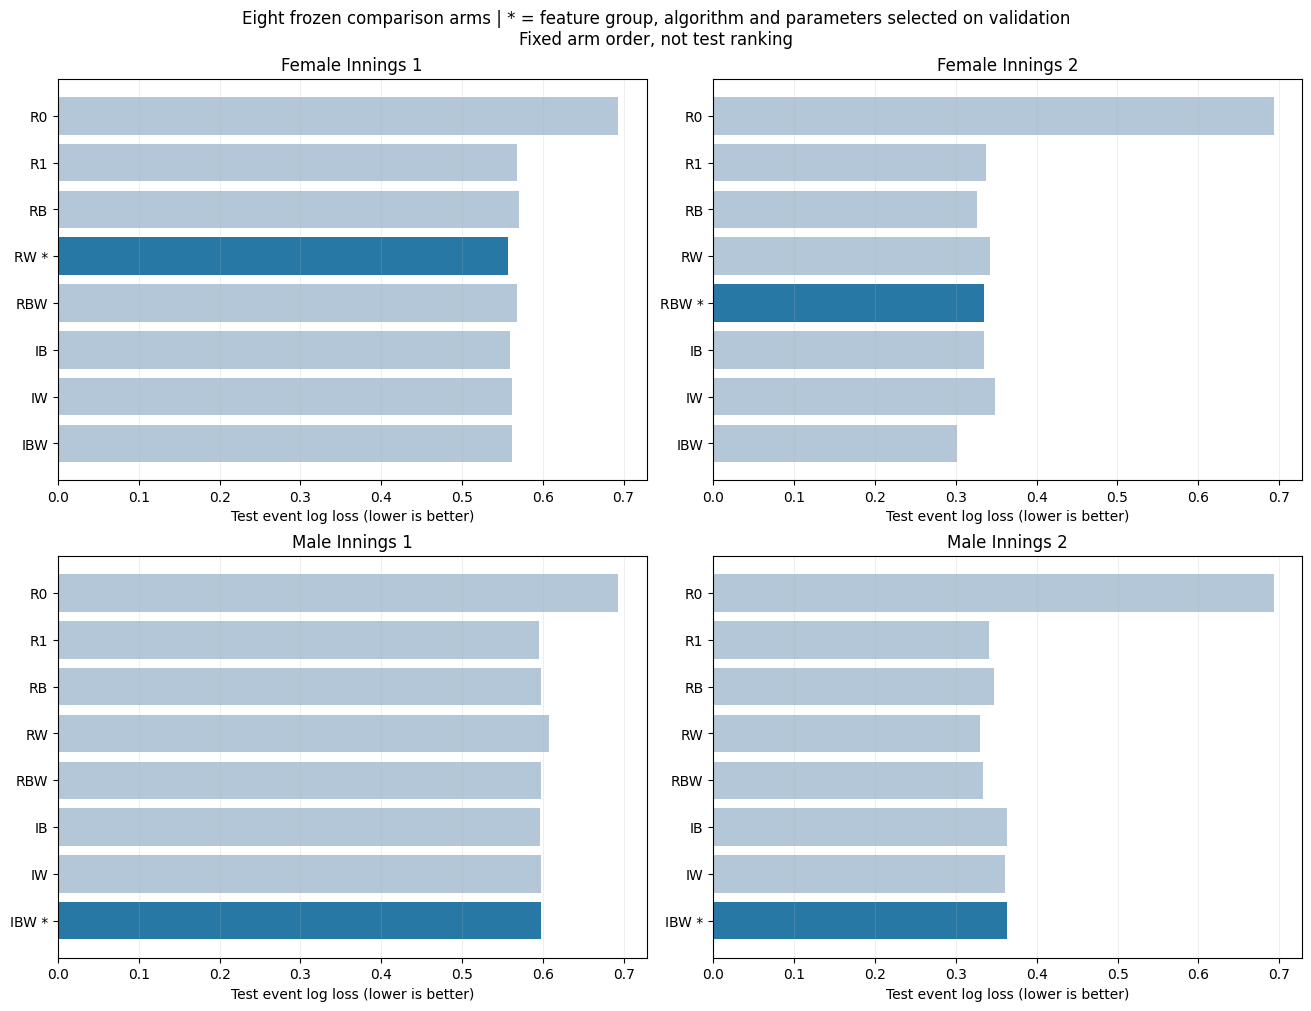

In [27]:
metrics = pd.read_csv(OUTPUT / 'test_metrics.csv')
show_details('All eight arms: detailed test metrics', metrics)
display(figures['test_log_loss.png'])


## 08.4 Calibration and support

Ten fixed-width bins, event-weighted ECE. Empty bins are unavailable; repeated deliveries from the same match are not independent outcomes. Curves evaluate calibration; they do not fit a calibrator. Match counts per bin are not additive across bins.


track,arm_code,test_event_log_loss,test_brier,test_ece
female_innings_1,R0,0.693743,0.250296,0.022447
female_innings_1,R1,0.567588,0.193974,0.109564
female_innings_1,RB,0.570973,0.196399,0.111266
female_innings_1,RW,0.556630,0.189293,0.107499
female_innings_1,RBW,0.567659,0.194783,0.093925
female_innings_1,IB,0.558975,0.191021,0.089522
female_innings_1,IW,0.561818,0.192870,0.096031
female_innings_1,IBW,0.562354,0.193164,0.121582
female_innings_2,R0,0.693083,0.249968,0.016481
female_innings_2,R1,0.336933,0.107419,0.071239


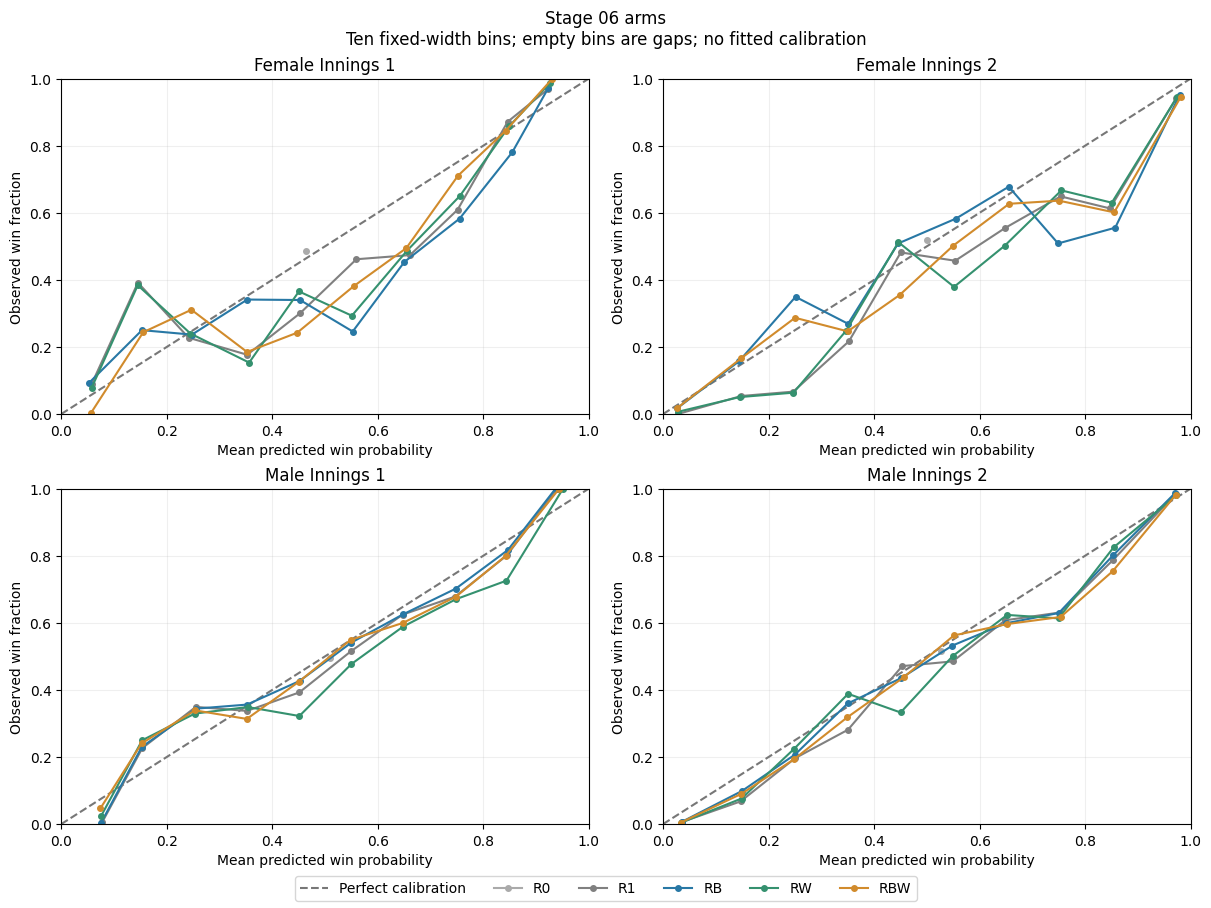

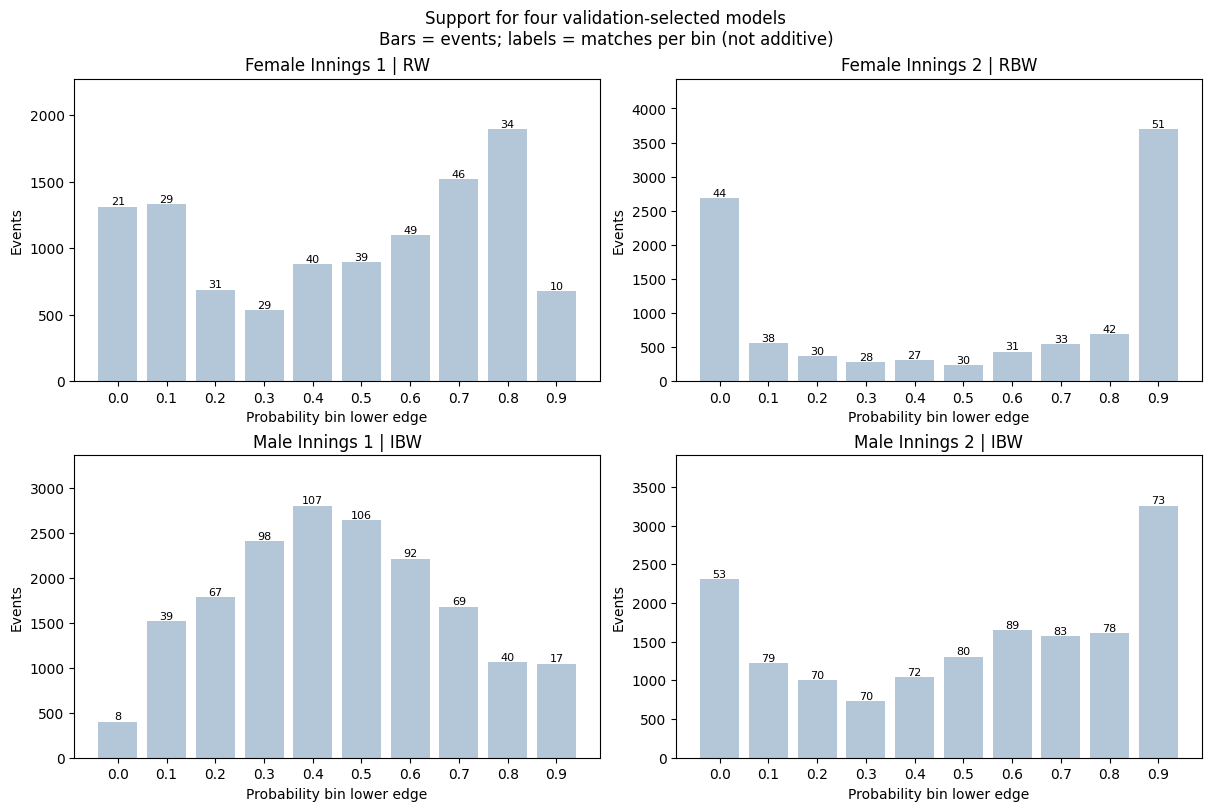

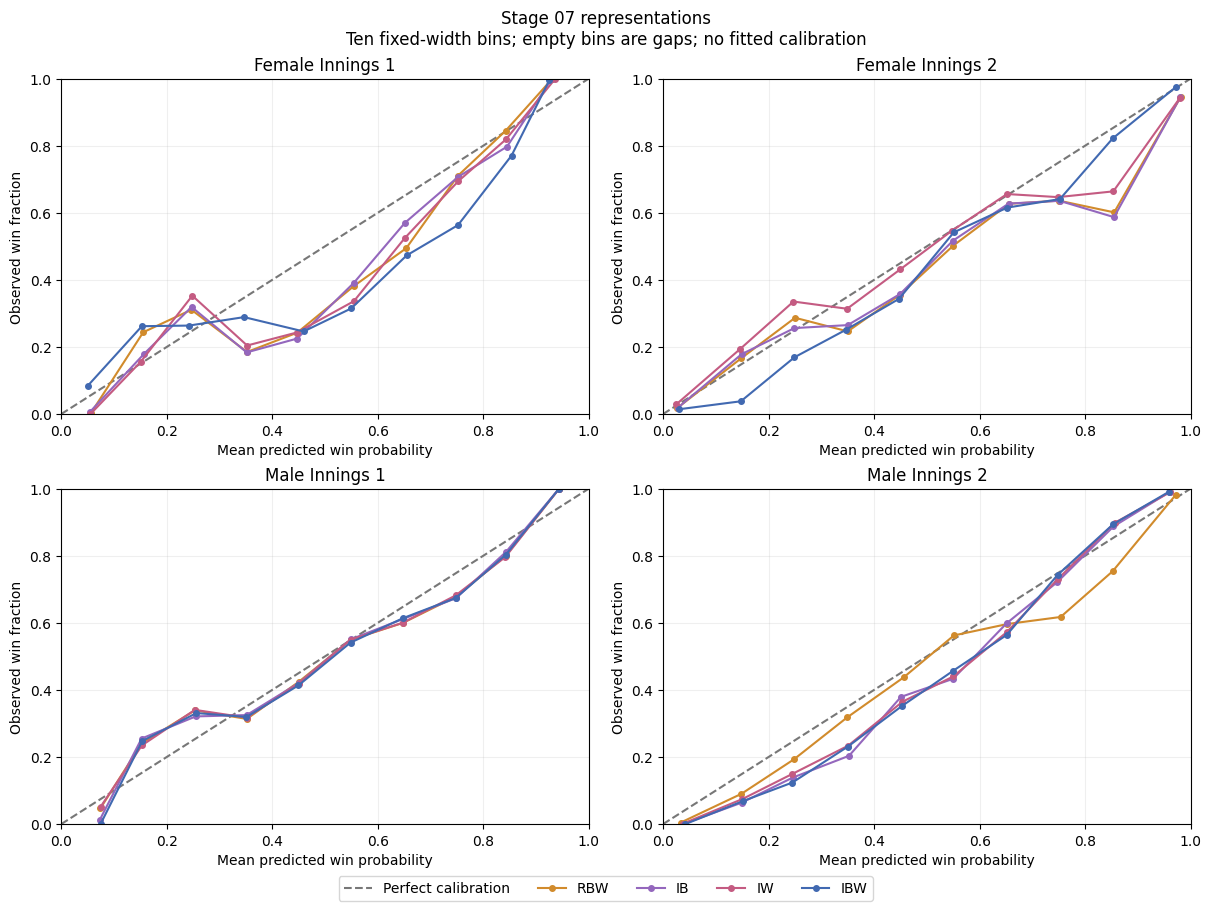

In [28]:
show_details('All eight arms: calibration metrics', metrics[['track', 'arm_code', 'test_event_log_loss', 'test_brier', 'test_ece']])
display(figures['calibration_main.png'])
display(figures['preferred_bin_support.png'])
display(figures['calibration_interactions.png'])


## 08.5 Paired comparisons and uncertainty

Retain the six resource contrasts (primary: RBW versus R1); add each interaction arm versus RBW and R1. Report all planned contrasts. Positive gain = reference loss minus treatment loss. Use 2,000 whole-match bootstrap replicates within gender, shared across innings and arms. The 95% pointwise intervals are not multiplicity-adjusted and omit model-selection uncertainty. A zero-spanning interval is inconclusive, not proof of no effect.


track,treatment,reference,comparison_role,metric,gain,ci_lower,ci_upper,contains_zero,matches,bootstrap_replicates
female_innings_1,RBW,R1,primary,event_log_loss,-0.000071,-0.048838,0.051249,True,87,2000
female_innings_1,RBW,R1,primary,match_log_loss,-0.000671,-0.049471,0.051204,True,87,2000
female_innings_1,RBW,R1,primary,brier,-0.000809,-0.019367,0.018550,True,87,2000
female_innings_1,RBW,R1,primary,match_brier,-0.001078,-0.019884,0.018286,True,87,2000
female_innings_2,RBW,R1,primary,event_log_loss,0.002202,-0.045116,0.041290,True,87,2000
female_innings_2,RBW,R1,primary,match_log_loss,0.005535,-0.038901,0.041681,True,87,2000
female_innings_2,RBW,R1,primary,brier,0.003551,-0.009954,0.015467,True,87,2000
female_innings_2,RBW,R1,primary,match_brier,0.004330,-0.008242,0.015607,True,87,2000
male_innings_1,RBW,R1,primary,event_log_loss,-0.001976,-0.016758,0.012439,True,141,2000
male_innings_1,RBW,R1,primary,match_log_loss,-0.001995,-0.016799,0.012252,True,141,2000


track,treatment,reference,comparison_role,metric,gain,ci_lower,ci_upper,contains_zero,matches,bootstrap_replicates
female_innings_1,RB,R1,supporting,event_log_loss,-0.003384,-0.042722,0.035537,True,87,2000
female_innings_1,RB,R1,supporting,match_log_loss,-0.004196,-0.043527,0.034802,True,87,2000
female_innings_1,RB,R1,supporting,brier,-0.002425,-0.017906,0.011963,True,87,2000
female_innings_1,RB,R1,supporting,match_brier,-0.002734,-0.018183,0.011638,True,87,2000
female_innings_1,RW,R1,supporting,event_log_loss,0.010958,-0.005980,0.027586,True,87,2000
female_innings_1,RW,R1,supporting,match_log_loss,0.010825,-0.006168,0.027326,True,87,2000
female_innings_1,RW,R1,supporting,brier,0.004681,-0.002614,0.011832,True,87,2000
female_innings_1,RW,R1,supporting,match_brier,0.004654,-0.002711,0.011804,True,87,2000
female_innings_1,RBW,RW,supporting,event_log_loss,-0.011029,-0.062649,0.041305,True,87,2000
female_innings_1,RBW,RW,supporting,match_log_loss,-0.011496,-0.063395,0.041197,True,87,2000


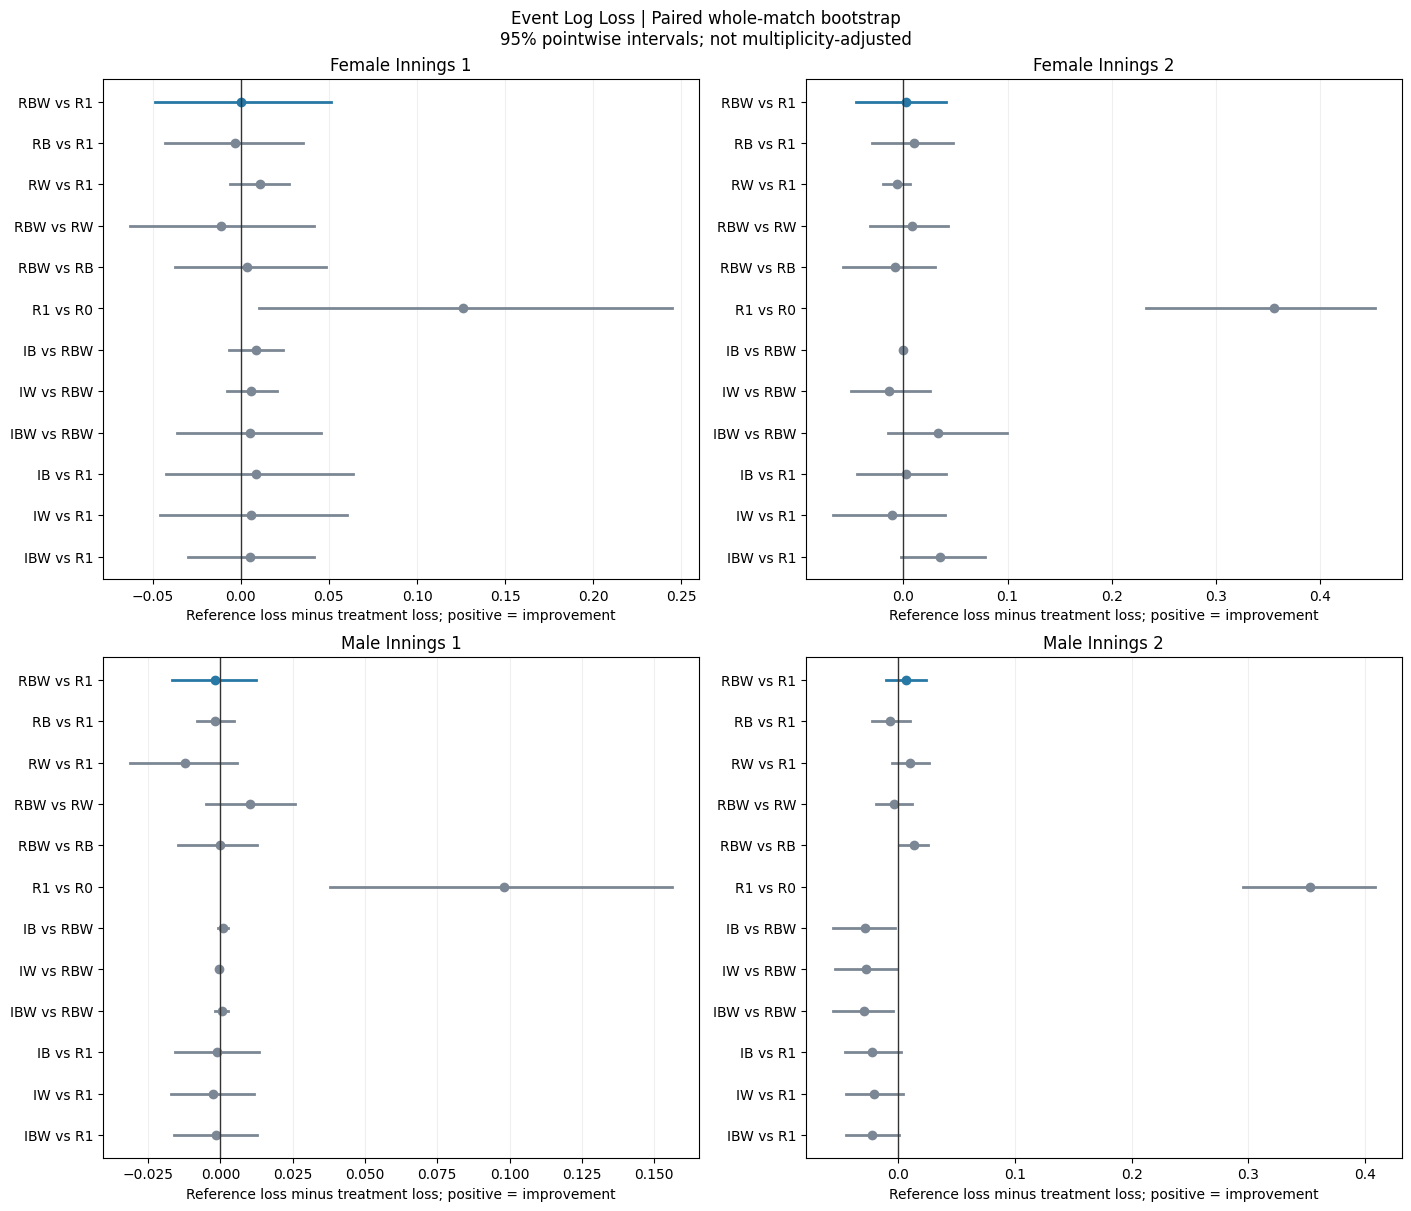

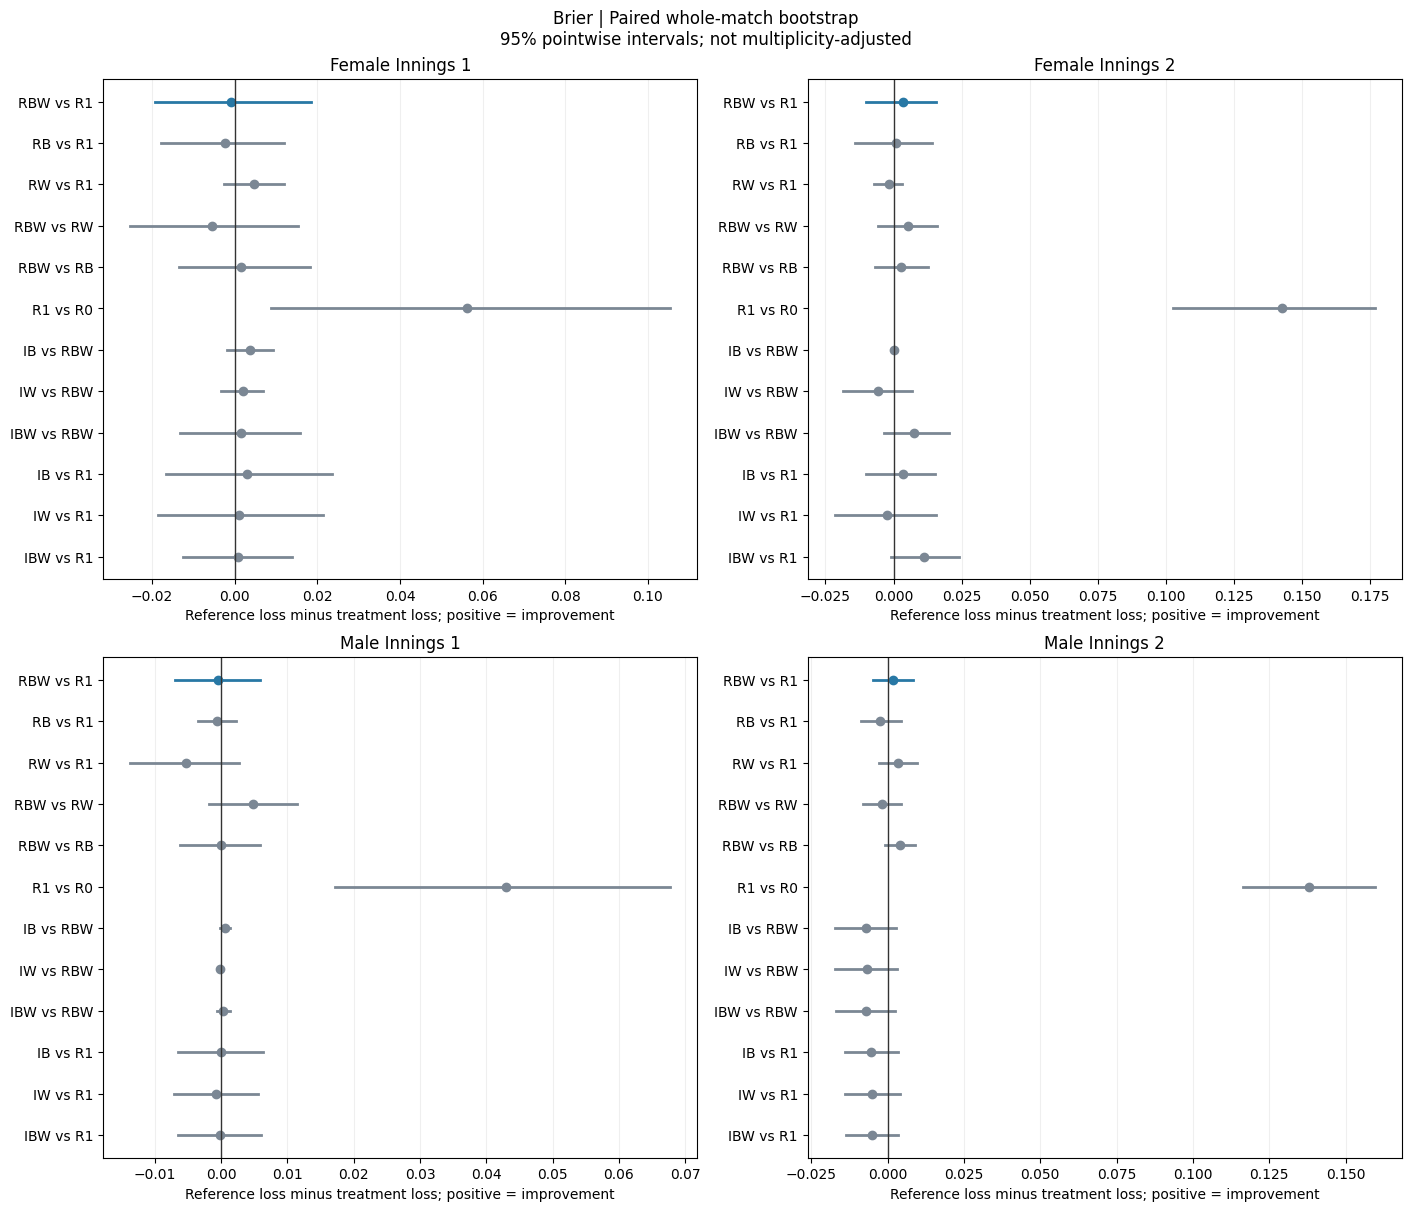

In [29]:
comparisons = pd.read_csv(OUTPUT / 'paired_comparisons.csv')
show_details('Primary paired comparisons', comparisons[comparisons.comparison_role.eq('primary')])
show_details('Supporting paired comparisons', comparisons[comparisons.comparison_role.eq('supporting')])
display(figures['paired_log_loss.png'])
display(figures['paired_brier.png'])


## 08.6 Selected-model feature and block importance

Explain the four validation-selected final models. Permute each actual input and each nonempty state/resource/interaction block using ten fixed-seed repeats. A block not present in a model is not evaluated; a constant model has no feature importance.

Interaction columns are shuffled separately; products are not reconstructed. Correlation and inconsistent combinations can distort marginal importance. Mean +/- shuffle SD is not a sampling confidence interval, causal effect or a reason to retune on test data. Keep negative values.

Native importance supplements the permutation results: W1 uses XGBoost mean split Gain; M2 uses Random Forest normalised mean decrease in impurity (MDI), not Gain. W2's installed HistGradientBoosting implementation has no public native Gain interface; Gain is not applicable to M1's Logistic Regression. Different metrics and models do not share a common scale.

Native tables list the exact transformed model columns and their original input names. One-hot phase indicators are separate; their average gains are not summed. Unused retained XGBoost features have zero Gain; removed constants have no score. These training-model summaries are descriptive, not causal or test-performance gains. RUN_NATIVE_IMPORTANCE controls explicit extraction from saved models, without training or prediction.


,track,arm_code,family,status
0,female_innings_1,RW,xgboost,evaluated
1,female_innings_2,RBW,hist_gradient_boosting,evaluated
2,male_innings_1,IBW,logistic_regression,evaluated
3,male_innings_2,IBW,random_forest,evaluated


track,arm_code,family,unit_type,unit,columns,importance_mean,importance_std,repeats,baseline_log_loss,events,matches,interpretation
female_innings_1,RW,xgboost,block,state_background,"[""pre_score"", ""wickets_remaining"", ""scheduled_balls_remaining_estimate"", ""current_run_rate"", ""no_legal_ball_yet"", ""toss_first_team_won"", ""first_team_prior_win_rate"", ""second_team_prior_win_rate"", ""first_team_recent_win_rate"", ""second_team_recent_win_rate"", ""innings_phase""]",0.432700,0.007102,10,0.556630,10824,87,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"
female_innings_1,RW,xgboost,block,bowling_resources,"[""bowling_resource_bowling_economy"", ""bowling_resource_bowling_wicket_rate"", ""bowling_resource_bowling_dot_rate""]",0.001257,0.000456,10,0.556630,10824,87,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"
female_innings_2,RBW,hist_gradient_boosting,block,state_background,"[""pre_score"", ""wickets_remaining"", ""scheduled_balls_remaining_estimate"", ""current_run_rate"", ""no_legal_ball_yet"", ""target_runs"", ""runs_required"", ""required_run_rate"", ""run_rate_differential"", ""toss_first_team_won"", ""first_team_prior_win_rate"", ""second_team_prior_win_rate"", ""first_team_recent_win_rate"", ""second_team_recent_win_rate"", ""innings_phase""]",1.243446,0.015707,10,0.334731,9785,87,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"
female_innings_2,RBW,hist_gradient_boosting,block,batting_resources,"[""waiting_resource_batting_strike_rate"", ""waiting_resource_batting_average"", ""waiting_resource_batting_boundary_rate"", ""waiting_resource_batting_dot_rate""]",0.062229,0.003061,10,0.334731,9785,87,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"
female_innings_2,RBW,hist_gradient_boosting,block,bowling_resources,"[""bowling_resource_bowling_economy"", ""bowling_resource_bowling_wicket_rate"", ""bowling_resource_bowling_dot_rate""]",0.002412,0.000507,10,0.334731,9785,87,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"
male_innings_1,IBW,logistic_regression,block,state_background,"[""pre_score"", ""wickets_remaining"", ""scheduled_balls_remaining_estimate"", ""current_run_rate"", ""no_legal_ball_yet"", ""toss_first_team_won"", ""first_team_prior_win_rate"", ""second_team_prior_win_rate"", ""first_team_recent_win_rate"", ""second_team_recent_win_rate"", ""innings_phase""]",0.564300,0.006446,10,0.597008,17537,141,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"
male_innings_1,IBW,logistic_regression,block,batting_resources,"[""waiting_resource_batting_strike_rate"", ""waiting_resource_batting_average"", ""waiting_resource_batting_boundary_rate"", ""waiting_resource_batting_dot_rate""]",0.010797,0.000891,10,0.597008,17537,141,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"
male_innings_1,IBW,logistic_regression,block,bowling_resources,"[""bowling_resource_bowling_economy"", ""bowling_resource_bowling_wicket_rate"", ""bowling_resource_bowling_dot_rate""]",0.403478,0.003755,10,0.597008,17537,141,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"
male_innings_1,IBW,logistic_regression,block,batting_interactions,"[""progress_interaction_waiting_resource_batting_strike_rate"", ""progress_interaction_waiting_resource_batting_average"", ""progress_interaction_waiting_resource_batting_boundary_rate"", ""progress_interaction_waiting_resource_batting_dot_rate""]",0.084690,0.001713,10,0.597008,17537,141,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"
male_innings_1,IBW,logistic_regression,block,bowling_interactions,"[""progress_interaction_bowling_resource_bowling_economy"", ""progress_interaction_bowling_resource_bowling_wicket_rate"", ""progress_interaction_bowling_resource_bowling_dot_rate""]",0.1

track,arm_code,family,unit_type,unit,columns,importance_mean,importance_std,repeats,baseline_log_loss,events,matches,interpretation
female_innings_1,RW,xgboost,feature,second_team_prior_win_rate,"[""second_team_prior_win_rate""]",0.107480,0.004209,10,0.55663,10824,87,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"
female_innings_1,RW,xgboost,feature,current_run_rate,"[""current_run_rate""]",0.091251,0.003675,10,0.55663,10824,87,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"
female_innings_1,RW,xgboost,feature,first_team_prior_win_rate,"[""first_team_prior_win_rate""]",0.047179,0.002489,10,0.55663,10824,87,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"
female_innings_1,RW,xgboost,feature,second_team_recent_win_rate,"[""second_team_recent_win_rate""]",0.025994,0.002129,10,0.55663,10824,87,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"
female_innings_1,RW,xgboost,feature,wickets_remaining,"[""wickets_remaining""]",0.017632,0.000803,10,0.55663,10824,87,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"
female_innings_1,RW,xgboost,feature,toss_first_team_won,"[""toss_first_team_won""]",0.011454,0.000607,10,0.55663,10824,87,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"
female_innings_1,RW,xgboost,feature,first_team_recent_win_rate,"[""first_team_recent_win_rate""]",0.009637,0.001120,10,0.55663,10824,87,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"
female_innings_1,RW,xgboost,feature,bowling_resource_bowling_economy,"[""bowling_resource_bowling_economy""]",0.003729,0.000301,10,0.55663,10824,87,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"
female_innings_1,RW,xgboost,feature,pre_score,"[""pre_score""]",0.003589,0.000466,10,0.55663,10824,87,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"
female_innings_1,RW,xgboost,feature,bowling_resource_bowling_dot_rate,"[""bowling_resource_bowling_dot_rate""]",0.000716,0.000057,10,0.55663,10824,87,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"


track,arm_code,family,unit_type,unit,columns,importance_mean,importance_std,repeats,baseline_log_loss,events,matches,interpretation
female_innings_2,RBW,hist_gradient_boosting,feature,required_run_rate,"[""required_run_rate""]",0.140942,0.004141,10,0.334731,9785,87,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"
female_innings_2,RBW,hist_gradient_boosting,feature,run_rate_differential,"[""run_rate_differential""]",0.082470,0.003880,10,0.334731,9785,87,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"
female_innings_2,RBW,hist_gradient_boosting,feature,waiting_resource_batting_boundary_rate,"[""waiting_resource_batting_boundary_rate""]",0.049810,0.002625,10,0.334731,9785,87,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"
female_innings_2,RBW,hist_gradient_boosting,feature,target_runs,"[""target_runs""]",0.038928,0.003136,10,0.334731,9785,87,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"
female_innings_2,RBW,hist_gradient_boosting,feature,second_team_prior_win_rate,"[""second_team_prior_win_rate""]",0.017913,0.003281,10,0.334731,9785,87,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"
female_innings_2,RBW,hist_gradient_boosting,feature,first_team_recent_win_rate,"[""first_team_recent_win_rate""]",0.016494,0.002762,10,0.334731,9785,87,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"
female_innings_2,RBW,hist_gradient_boosting,feature,runs_required,"[""runs_required""]",0.014852,0.001588,10,0.334731,9785,87,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"
female_innings_2,RBW,hist_gradient_boosting,feature,first_team_prior_win_rate,"[""first_team_prior_win_rate""]",0.011538,0.001851,10,0.334731,9785,87,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"
female_innings_2,RBW,hist_gradient_boosting,feature,waiting_resource_batting_average,"[""waiting_resource_batting_average""]",0.005862,0.000449,10,0.334731,9785,87,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"
female_innings_2,RBW,hist_gradient_boosting,feature,pre_score,"[""pre_score""]",0.005549,0.000634,10,0.334731,9785,87,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"


track,arm_code,family,unit_type,unit,columns,importance_mean,importance_std,repeats,baseline_log_loss,events,matches,interpretation
male_innings_1,IBW,logistic_regression,feature,pre_score,"[""pre_score""]",0.470855,0.006559,10,0.597008,17537,141,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"
male_innings_1,IBW,logistic_regression,feature,bowling_resource_bowling_dot_rate,"[""bowling_resource_bowling_dot_rate""]",0.261651,0.002876,10,0.597008,17537,141,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"
male_innings_1,IBW,logistic_regression,feature,waiting_resource_batting_strike_rate,"[""waiting_resource_batting_strike_rate""]",0.108090,0.002866,10,0.597008,17537,141,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"
male_innings_1,IBW,logistic_regression,feature,wickets_remaining,"[""wickets_remaining""]",0.081335,0.002431,10,0.597008,17537,141,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"
male_innings_1,IBW,logistic_regression,feature,second_team_prior_win_rate,"[""second_team_prior_win_rate""]",0.059386,0.001976,10,0.597008,17537,141,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"
male_innings_1,IBW,logistic_regression,feature,progress_interaction_waiting_resource_batting_strike_rate,"[""progress_interaction_waiting_resource_batting_strike_rate""]",0.055993,0.001370,10,0.597008,17537,141,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"
male_innings_1,IBW,logistic_regression,feature,waiting_resource_batting_boundary_rate,"[""waiting_resource_batting_boundary_rate""]",0.053285,0.002562,10,0.597008,17537,141,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"
male_innings_1,IBW,logistic_regression,feature,progress_interaction_bowling_resource_bowling_wicket_rate,"[""progress_interaction_bowling_resource_bowling_wicket_rate""]",0.046017,0.001414,10,0.597008,17537,141,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"
male_innings_1,IBW,logistic_regression,feature,waiting_resource_batting_dot_rate,"[""waiting_resource_batting_dot_rate""]",0.037508,0.001885,10,0.597008,17537,141,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"
male_innings_1,IBW,logistic_regression,feature,first_team_recent_win_rate,"[""first_team_recent_win_rate""]",0.033581,0.001352,10,0.597008,17537,141,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"


track,arm_code,family,unit_type,unit,columns,importance_mean,importance_std,repeats,baseline_log_loss,events,matches,interpretation
male_innings_2,IBW,random_forest,feature,required_run_rate,"[""required_run_rate""]",0.100931,0.001832,10,0.363352,15704,141,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"
male_innings_2,IBW,random_forest,feature,run_rate_differential,"[""run_rate_differential""]",0.069241,0.001510,10,0.363352,15704,141,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"
male_innings_2,IBW,random_forest,feature,runs_required,"[""runs_required""]",0.032431,0.000976,10,0.363352,15704,141,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"
male_innings_2,IBW,random_forest,feature,target_runs,"[""target_runs""]",0.030198,0.001082,10,0.363352,15704,141,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"
male_innings_2,IBW,random_forest,feature,waiting_resource_batting_boundary_rate,"[""waiting_resource_batting_boundary_rate""]",0.017940,0.000304,10,0.363352,15704,141,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"
male_innings_2,IBW,random_forest,feature,waiting_resource_batting_strike_rate,"[""waiting_resource_batting_strike_rate""]",0.016823,0.000300,10,0.363352,15704,141,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"
male_innings_2,IBW,random_forest,feature,waiting_resource_batting_average,"[""waiting_resource_batting_average""]",0.011874,0.000184,10,0.363352,15704,141,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"
male_innings_2,IBW,random_forest,feature,waiting_resource_batting_dot_rate,"[""waiting_resource_batting_dot_rate""]",0.008057,0.000115,10,0.363352,15704,141,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"
male_innings_2,IBW,random_forest,feature,wickets_remaining,"[""wickets_remaining""]",0.005301,0.000087,10,0.363352,15704,141,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"
male_innings_2,IBW,random_forest,feature,second_team_prior_win_rate,"[""second_team_prior_win_rate""]",0.004231,0.000496,10,0.363352,15704,141,"descriptive marginal reliance; shuffle SD, not confidence interval or causal effect"


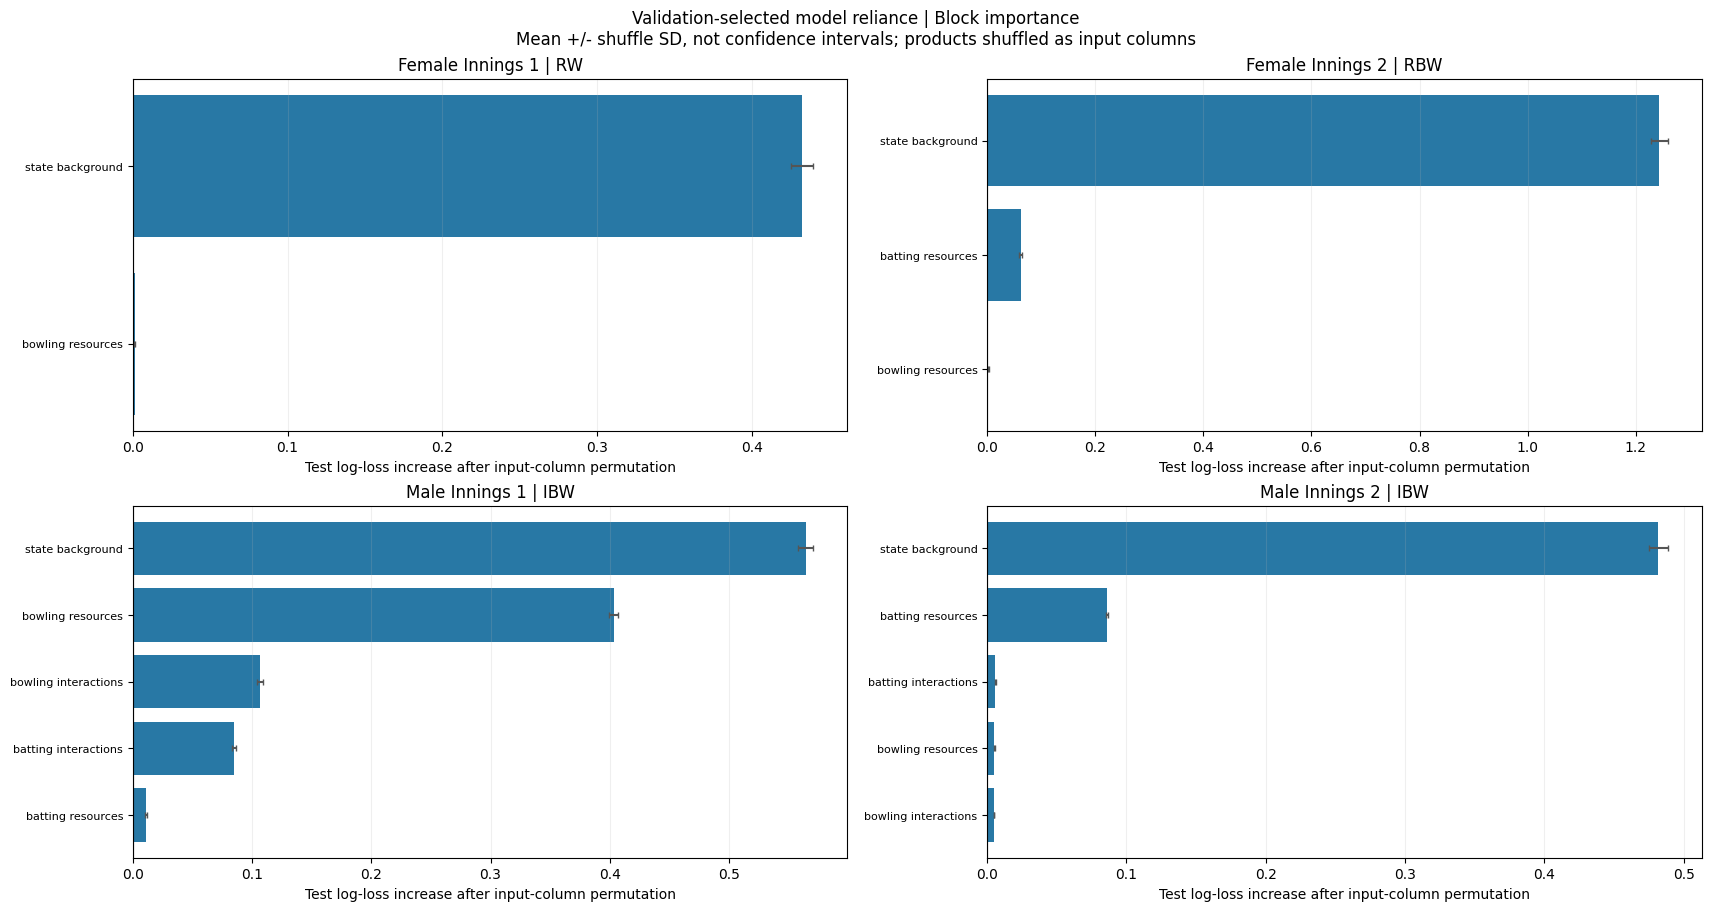

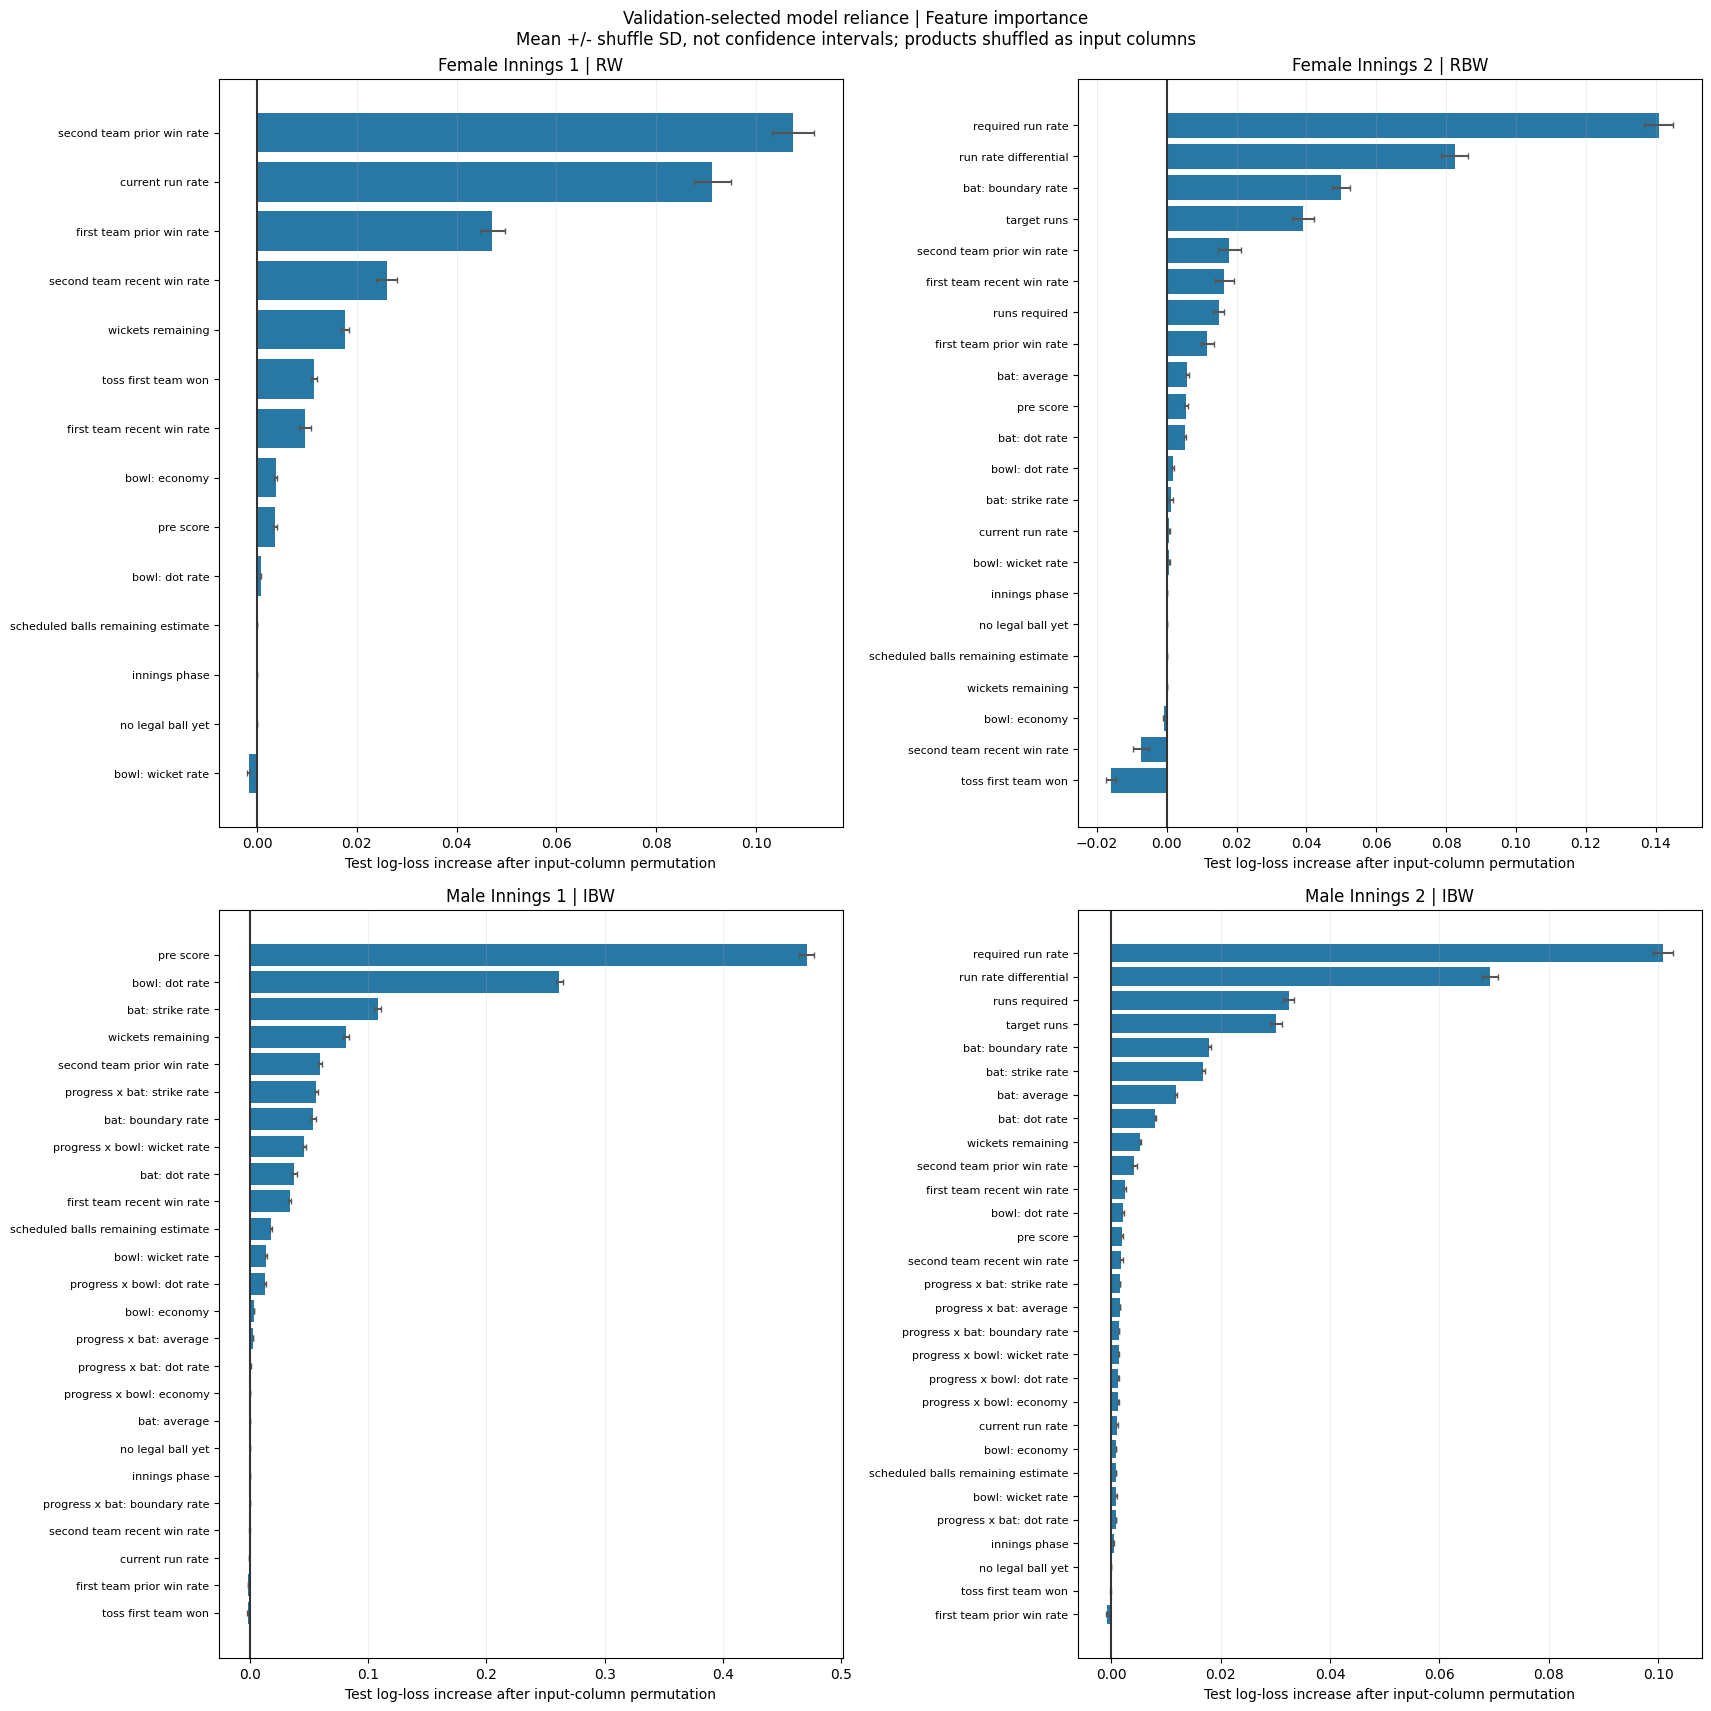

Native importance supplement: 0dad5601e833a8bee70ab1e685b65e1c96591f8b18699a3c9ed6bcd54ba5ade4


,track,arm_code,family,metric,status,explanation
0,female_innings_1,RW,xgboost,xgboost_mean_split_gain,exported,Mean gain over training splits using each tran...
1,female_innings_2,RBW,hist_gradient_boosting,not_exported,unsupported_public_interface,Installed HistGradientBoosting has no public G...
2,male_innings_1,IBW,logistic_regression,not_applicable,not_applicable_linear_model,Logistic Regression is not a tree model; coeff...
3,male_innings_2,IBW,random_forest,random_forest_normalized_mdi,exported,Normalised mean decrease in impurity across tr...


feature,raw_feature,metric,importance,retained,status,used_in_split
current_run_rate,current_run_rate,xgboost_mean_split_gain,794.903442,True,retained,True
second_team_prior_win_rate,second_team_prior_win_rate,xgboost_mean_split_gain,375.226501,True,retained,True
first_team_recent_win_rate,first_team_recent_win_rate,xgboost_mean_split_gain,303.716583,True,retained,True
first_team_prior_win_rate,first_team_prior_win_rate,xgboost_mean_split_gain,244.152130,True,retained,True
second_team_recent_win_rate,second_team_recent_win_rate,xgboost_mean_split_gain,240.111649,True,retained,True
toss_first_team_won,toss_first_team_won,xgboost_mean_split_gain,226.558975,True,retained,True
wickets_remaining,wickets_remaining,xgboost_mean_split_gain,221.616730,True,retained,True
bowling_resource_bowling_dot_rate,bowling_resource_bowling_dot_rate,xgboost_mean_split_gain,159.612183,True,retained,True
pre_score,pre_score,xgboost_mean_split_gain,89.498795,True,retained,True
scheduled_balls_remaining_estimate,scheduled_balls_remaining_estimate,xgboost_mean_split_gain,80.047539,True,retained,True


feature,raw_feature,metric,importance,retained,status,used_in_split
required_run_rate,required_run_rate,random_forest_normalized_mdi,0.245917,True,retained,NaN
run_rate_differential,run_rate_differential,random_forest_normalized_mdi,0.181118,True,retained,NaN
target_runs,target_runs,random_forest_normalized_mdi,0.115138,True,retained,NaN
runs_required,runs_required,random_forest_normalized_mdi,0.070145,True,retained,NaN
waiting_resource_batting_strike_rate,waiting_resource_batting_strike_rate,random_forest_normalized_mdi,0.045046,True,retained,NaN
waiting_resource_batting_average,waiting_resource_batting_average,random_forest_normalized_mdi,0.044798,True,retained,NaN
waiting_resource_batting_boundary_rate,waiting_resource_batting_boundary_rate,random_forest_normalized_mdi,0.043592,True,retained,NaN
second_team_prior_win_rate,second_team_prior_win_rate,random_forest_normalized_mdi,0.042974,True,retained,NaN
waiting_resource_batting_dot_rate,waiting_resource_batting_dot_rate,random_forest_normalized_mdi,0.025028,True,retained,NaN
first_team_recent_win_rate,first_team_recent_win_rate,random_forest_normalized_mdi,0.024870,True,retained,NaN


In [30]:
importance = pd.read_csv(OUTPUT / 'feature_importance.csv')
display(pd.read_csv(OUTPUT / 'importance_status.csv'))
show_details('Feature-block importance: full table', importance[importance.unit_type.eq('block')])
for track in stage.TRACKS:
    show_details(f"{track} | {summary['preferred'][track]}: full feature importance", importance[importance.track.eq(track) & importance.unit_type.eq('feature')].sort_values('importance_mean', ascending=False))
display(figures['resource_block_importance.png'])
display(figures['feature_importance.png'])

if RUN_NATIVE_IMPORTANCE:
    native_importance.run(ROOT)
native_summary, native_features, native_status = native_importance.load_tables(ROOT)
print('Native importance supplement:', native_summary['native_importance_id'])
display(native_status[['track', 'arm_code', 'family', 'metric', 'status', 'explanation']])
for track in stage.TRACKS:
    native_part = native_features[native_features.track.eq(track)]
    if not native_part.empty:
        show_details(f'{track}: native importance per transformed feature', native_part[['feature', 'raw_feature', 'metric', 'importance', 'retained', 'status', 'used_in_split']].sort_values('importance', ascending=False, na_position='last'))
show_details('Native importance definitions and limitations', '\n'.join(native_summary['notes']))


## 08.7 Raw-probability handoff contract

Export four validation-selected raw probability streams, one prediction per test event. Reports and data use `resource_sums_v2_joint_selection_v1`. The handoff records each track's feature group, algorithm, model hash, input columns and prediction path.

A downstream consumer must verify this contract and the four model identities before using the stream. Stage 08 exports raw pre-event probabilities; terminal outcome accounting and player allocation are separate from probability evaluation.


In [31]:
handoff = json.loads((OUTPUT / 'nwc_handoff.json').read_text(encoding='utf-8'))
show_details('Stage 09 handoff: model identities and file paths', pd.DataFrame(handoff['preferred_models'])[['track', 'arm_code', 'family', 'model_path']])
print('Raw predictions:', ROOT / handoff['prediction_path'])
print('Reports and charts:', OUTPUT)
limitations = summary['limitations']
show_details('Method limitations and interpretation notes', '\n'.join('- ' + item for item in limitations))


track,arm_code,family,model_path
female_innings_1,RW,xgboost,outputs/06_model_training_and_comparison/models/resource_sums_v2/female_innings_1__bowling_resources__xgboost.joblib
female_innings_2,RBW,hist_gradient_boosting,outputs/06_model_training_and_comparison/models/resource_sums_v2/female_innings_2__both_resources__hist_gradient_boosting.joblib
male_innings_1,IBW,logistic_regression,outputs/07_resource_representation_experiments/resource_sums_v2/four_way_interactions_v1/ibw/models/male_innings_1__IBW__logistic_regression__candidate_0.joblib
male_innings_2,IBW,random_forest,outputs/07_resource_representation_experiments/resource_sums_v2/four_way_interactions_v1/ibw/models/male_innings_2__IBW__random_forest__candidate_0.joblib


Raw predictions: d:\T20_Project\T20_Project_3.0\data\processed\probability_evaluation\resource_sums_v2_joint_selection_v1\preferred_test_predictions.csv.gz
Reports and charts: d:\T20_Project\T20_Project_3.0\outputs\08_probability_evaluation\resource_sums_v2_joint_selection_v1
